# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Radhitya Gervany Yahya
- **Email:** ds009b6y1464@student.devacademy.id
- **ID Dicoding:** DS009B6Y1464

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Dataset yang digunakan adalah *Brazilian E-Commerce Public Dataset* (Olist). Periode pesanan yang dianalisis adalah
**Januari 2017 – Agustus 2018**, karena pada periode ini data tercatat lengkap per bulan (data 2016 dan September–Oktober 2018 sangat sedikit).

- **Pertanyaan 1:** Kategori produk apa saja yang menjadi 5 penyumbang revenue tertinggi dan 5 terendah selama Januari 2017 – Agustus 2018, berapa kontribusi 5 kategori teratas terhadap total revenue, dan bagaimana tren revenue bulanannya?
   - *Specific*: fokus pada revenue per kategori produk dan tren bulanan.
   - *Measurable*: revenue (jumlah `price`), persentase kontribusi, dan revenue bulanan.
   - *Action-oriented*: hasilnya menentukan kategori yang diprioritaskan untuk stok/promosi dan kategori yang perlu dievaluasi.
   - *Relevant*: revenue adalah indikator utama kinerja bisnis e-commerce.
   - *Time-bound*: Januari 2017 – Agustus 2018.

- **Pertanyaan 2:** Di 10 state dengan jumlah pesanan terbanyak, berapa persentase pesanan yang terlambat tiba dan berapa rata-rata review score pada Januari 2017 – Agustus 2018, serta seberapa besar selisih review score antara pesanan tepat waktu dan terlambat?
   - *Specific*: keterlambatan pengiriman (tanggal diterima > estimasi) dan review score pada 10 state teratas.
   - *Measurable*: persentase keterlambatan, rata-rata review score, selisih skor.
   - *Action-oriented*: menunjukkan wilayah yang perlu diperbaiki logistiknya terlebih dahulu.
   - *Relevant*: kepuasan pelanggan berkaitan langsung dengan retensi dan reputasi toko.
   - *Time-bound*: Januari 2017 – Agustus 2018.

- **Pertanyaan 3 (analisis lanjutan):** Berapa persentase pelanggan yang melakukan pembelian ulang dan bagaimana segmentasi pelanggan berdasarkan RFM (Recency, Frequency, Monetary) dengan tanggal acuan 30 Agustus 2018 (sehari setelah transaksi terakhir)?
   - Digunakan untuk menentukan segmen pelanggan yang layak dijadikan target kampanye retensi.

## Import Semua Packages/Library yang Digunakan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")

# Palet: satu warna sorot untuk pesan utama, abu-abu untuk pembanding (mengurangi distraksi)
BLUE, LIGHT_BLUE, GREY, RED = "#1f6fb2", "#9bbfdc", "#c4c9cf", "#d9534f"

def clean_axes(ax):
    # hapus garis grid dan spine yang tidak perlu (data-ink ratio)
    ax.grid(False)
    sns.despine(ax=ax)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Data Wrangling

### Gathering Data

#### Load df orders, order_items, order_reviews, products, translation, dan customers

Tabel yang dibutuhkan untuk menjawab pertanyaan bisnis: `orders` (status & tanggal), `order_items` (harga & produk),
`order_reviews` (review score), `products` + `product_category_name_translation` (kategori produk), dan `customers` (state & ID unik pelanggan).

In [ ]:
orders_df = pd.read_csv("data/orders_dataset.csv")
items_df = pd.read_csv("data/order_items_dataset.csv")
reviews_df = pd.read_csv("data/order_reviews_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")
translation_df = pd.read_csv("data/product_category_name_translation.csv")
customers_df = pd.read_csv("data/customers_dataset.csv")

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [ ]:
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,"1,000.00",30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.00,402.00,4.00,625.00,20.00,17.00,13.00


In [ ]:
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


**Insight:**
- Setiap tabel berhasil dimuat. Kunci penghubung: `order_id` (orders, items, reviews), `product_id` (items, products), `customer_id` (orders, customers), dan `product_category_name` (products, translation).
- Kolom tanggal pada `orders` masih bertipe teks sehingga perlu diubah ke `datetime`.

### Assessing Data

#### Identifying data quality problems (ringkasan semua tabel)

In [ ]:
tables = {
    "orders": orders_df, "order_items": items_df, "order_reviews": reviews_df,
    "products": products_df, "translation": translation_df, "customers": customers_df,
}
summary = pd.DataFrame({
    name: {
        "baris": df.shape[0],
        "kolom": df.shape[1],
        "total missing value": int(df.isna().sum().sum()),
        "duplikat (baris penuh)": int(df.duplicated().sum()),
    } for name, df in tables.items()
}).T
summary

,baris,kolom,total missing value,duplikat (baris penuh)
orders,99441,8,4908,0
order_items,112650,7,0,0
order_reviews,99224,7,145903,0
products,32951,9,2448,0
translation,71,2,0,0
customers,99441,5,0,0


#### Identifying orders problem

In [ ]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders_check = orders_df.copy()
orders_check[date_cols] = orders_check[date_cols].apply(pd.to_datetime)

print("Missing value per kolom:")
print(orders_check.isna().sum()[orders_check.isna().sum() > 0], "\n")
print("Distribusi order_status:")
print(orders_check["order_status"].value_counts(), "\n")
print("Rentang tanggal pembelian:", orders_check["order_purchase_timestamp"].min(), "s/d", orders_check["order_purchase_timestamp"].max(), "\n")

delivered = orders_check[orders_check["order_status"] == "delivered"]
print("Status 'delivered' tetapi tanggal diterima pelanggan kosong:", delivered["order_delivered_customer_date"].isna().sum())
canceled = orders_check[orders_check["order_status"] == "canceled"]
print("Status 'canceled' tetapi tanggal diterima pelanggan terisi:", canceled["order_delivered_customer_date"].notna().sum(), "\n")

print("Jumlah pesanan per bulan:")
print(orders_check.groupby(orders_check["order_purchase_timestamp"].dt.to_period("M")).size().to_string())

Missing value per kolom:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

Distribusi order_status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Rentang tanggal pembelian: 2016-09-04 21:15:19 s/d 2018-10-17 17:30:18 

Status 'delivered' tetapi tanggal diterima pelanggan kosong: 8
Status 'canceled' tetapi tanggal diterima pelanggan terisi: 6 

Jumlah pesanan per bulan:
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08  

#### Identifying order_reviews problem

In [ ]:
print("Order dengan lebih dari 1 review:", reviews_df["order_id"].duplicated().sum())
print("Order tanpa review:", orders_df["order_id"].nunique() - reviews_df["order_id"].nunique())
print(reviews_df["review_score"].value_counts().sort_index())

Order dengan lebih dari 1 review: 551
Order tanpa review: 768
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


#### Identifying products and translation problem

In [ ]:
print("Produk tanpa kategori:", products_df["product_category_name"].isna().sum())
missing_translation = set(products_df["product_category_name"].dropna()) - set(translation_df["product_category_name"])
print("Kategori yang tidak ada di tabel translasi:", missing_translation)

Produk tanpa kategori: 610
Kategori yang tidak ada di tabel translasi: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


#### Identifying order_items (outlier harga) and customers problem

In [ ]:
q1, q3 = items_df["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(items_df["price"].describe())
print(f"\nBatas atas outlier (IQR): {upper:,.2f} | jumlah item di atas batas: {(items_df['price'] > upper).sum()}")
print(f"\nJumlah customer_id: {customers_df['customer_id'].nunique():,} | jumlah customer_unique_id: {customers_df['customer_unique_id'].nunique():,}")

count   112,650.00
mean        120.65
std         183.63
min           0.85
25%          39.90
50%          74.99
75%         134.90
max       6,735.00
Name: price, dtype: float64

Batas atas outlier (IQR): 277.40 | jumlah item di atas batas: 8427

Jumlah customer_id: 99,441 | jumlah customer_unique_id: 96,096


**Steps to Take:**

Masalah kualitas data yang ditemukan beserta rencana penanganannya:

| No | Tabel | Masalah | Jenis | Tindakan pada Cleaning Data |
|----|-------|---------|-------|-----------------------------|
| 1 | `orders` | Kolom tanggal bertipe teks | Inconsistent value (tipe data) | Ubah ke `datetime` |
| 2 | `orders` | Tanggal diterima pelanggan kosong untuk status `delivered` (8 baris), padahal sudah dianggap selesai; pesanan `canceled` bahkan ada yang punya tanggal diterima | Missing value & inaccurate value | Gunakan hanya pesanan `delivered` dan buang baris tanpa tanggal diterima |
| 3 | `orders` | Data 2016 dan Sep–Okt 2018 sangat sedikit | Inconsistent value (cakupan periode) | Batasi periode analisis Jan 2017 – Agu 2018 |
| 4 | `order_reviews` | Ada order dengan lebih dari 1 review (551 duplikasi `order_id`) | Duplicate data | Ambil review terbaru per `order_id` |
| 5 | `order_reviews` | Sebagian order tidak punya review | Missing value | Dibiarkan kosong; tidak dihitung dalam rata-rata review score |
| 6 | `products` | 610 produk tanpa kategori | Missing value | Isi dengan `unknown`; dikeluarkan dari analisis per kategori |
| 7 | `translation` | 2 kategori (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`) tidak punya terjemahan | Missing value | Tambahkan terjemahan secara manual |
| 8 | `order_items` | Harga sangat tinggi (maks 6.735) di atas batas IQR | Outlier | Dipertahankan, karena wajar untuk produk bernilai tinggi dan bukan kesalahan input |
| 9 | `customers` | Satu pelanggan bisa punya beberapa `customer_id` | Inconsistent value | Gunakan `customer_unique_id` untuk analisis pelanggan |

### Cleaning Data

#### Fixing orders problem: tipe tanggal, status pesanan, tanggal kosong, dan periode

In [ ]:
orders_clean = orders_df.copy()
for col in date_cols:
    orders_clean[col] = pd.to_datetime(orders_clean[col])

orders_clean = orders_clean[orders_clean["order_status"] == "delivered"]
orders_clean = orders_clean.dropna(subset=["order_delivered_customer_date"])
orders_clean = orders_clean[
    (orders_clean["order_purchase_timestamp"] >= "2017-01-01")
    & (orders_clean["order_purchase_timestamp"] < "2018-09-01")
]
print("Jumlah pesanan setelah cleaning:", len(orders_clean))
orders_clean.isna().sum()[orders_clean.isna().sum() > 0]

Jumlah pesanan setelah cleaning: 96203


order_approved_at               14
order_delivered_carrier_date     1
dtype: int64

#### Fixing order_reviews problem: review ganda

In [ ]:
reviews_clean = (
    reviews_df.assign(review_answer_timestamp=pd.to_datetime(reviews_df["review_answer_timestamp"]))
    .sort_values("review_answer_timestamp")
    .drop_duplicates(subset="order_id", keep="last")
    [["order_id", "review_score"]]
)
print("Duplikasi order_id pada review:", reviews_clean["order_id"].duplicated().sum())

Duplikasi order_id pada review: 0


#### Fixing products and translation problem: kategori kosong dan tanpa terjemahan

In [ ]:
missing_rows = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"],
})
translation_clean = pd.concat([translation_df, missing_rows], ignore_index=True)

products_clean = products_df.merge(translation_clean, how="left", on="product_category_name")
products_clean["product_category"] = products_clean["product_category_name_english"].fillna("unknown")
products_clean = products_clean[["product_id", "product_category"]]
print(products_clean["product_category"].eq("unknown").sum(), "produk berkategori 'unknown'")

610 produk berkategori 'unknown'


#### Merging all tables into the main DataFrame

In [ ]:
all_df = (
    orders_clean
    .merge(items_df, on="order_id", how="inner")
    .merge(products_clean, on="product_id", how="left")
    .merge(customers_df[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
    .merge(reviews_clean, on="order_id", how="left")
)

# kolom turunan
all_df["delivery_days"] = (all_df["order_delivered_customer_date"] - all_df["order_purchase_timestamp"]).dt.days
all_df["is_late"] = (
    all_df["order_delivered_customer_date"].dt.normalize() > all_df["order_estimated_delivery_date"].dt.normalize()
)

main_cols = ["order_id", "customer_unique_id", "customer_state", "order_purchase_timestamp",
             "order_delivered_customer_date", "order_estimated_delivery_date", "product_category",
             "price", "freight_value", "review_score", "delivery_days", "is_late"]
all_df = all_df[main_cols]

print(all_df.shape)
all_df.isna().sum()[all_df.isna().sum() > 0]

(109872, 12)


review_score    823
dtype: int64

In [ ]:
all_df.head()

,order_id,customer_unique_id,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,product_category,price,freight_value,review_score,delivery_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,housewares,29.99,8.72,4.00,8,False
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,perfumery,118.70,22.76,4.00,13,False
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,auto,159.90,19.22,5.00,9,False
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,RN,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,pet_shop,45.00,27.20,5.00,13,False
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,SP,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,stationery,19.90,8.72,5.00,2,False


In [ ]:
# Simpan data bersih untuk dashboard
all_df.to_csv("dashboard/main_data.csv", index=False)

**Insight:**
- Data utama berisi satu baris per item pesanan untuk pesanan `delivered` periode Jan 2017 – Agu 2018, tanpa duplikasi review, dan kolom tanggal yang dipakai (pembelian, diterima pelanggan, estimasi) tidak ada yang kosong.
- Satu-satunya nilai kosong tersisa adalah `review_score` (pesanan tanpa review), yang memang tidak dihitung pada rata-rata skor.
- Data ini disimpan sebagai `dashboard/main_data.csv` untuk dipakai oleh dashboard Streamlit.

## Exploratory Data Analysis (EDA)

### Explore Data Utama

In [ ]:
all_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,109872,96203,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_unique_id,109872,93096,c8460e4251689ba205045f3ea17884a1,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,109872,27,SP,46331,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_purchase_timestamp,109872,NaN,NaN,NaN,2018-01-03 09:57:09.801669,2017-01-05 11:56:06,2017-09-16 19:23:19.250000,2018-01-21 21:53:51.500000,2018-05-05 21:22:12.750000,2018-08-29 15:00:37,NaN
order_delivered_customer_date,109872,NaN,NaN,NaN,2018-01-15 20:46:28.678744,2017-01-11 13:14:05,2017-09-27 22:39:15,2018-02-03 15:51:28,2018-05-15 21:47:47.750000,2018-10-17 13:22:46,NaN
order_estimated_delivery_date,109872,NaN,NaN,NaN,2018-01-27 03:04:08.492791,2017-02-01 00:00:00,2017-10-09 00:00:00,2018-02-16 00:00:00,2018-05-28 00:00:00,2018-10-25 00:00:00,NaN
product_category,109872,74,bed_bath_table,10945,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,"109,872.00",NaN,NaN,NaN,119.96,0.85,39.90,74.90,134.04,"6,735.00",182.35
freight_value,"109,872.00",NaN,NaN,NaN,19.95,0.00,13.08,16.26,21.15,409.68,15.70
review_score,"109,049.00",NaN,NaN,NaN,4.08,1.00,4.00,5.00,5.00,5.00,1.35


In [ ]:
print("Jumlah pesanan unik   :", all_df["order_id"].nunique())
print("Jumlah pelanggan unik :", all_df["customer_unique_id"].nunique())
print("Jumlah kategori produk:", all_df["product_category"].nunique())
print(f"Total revenue (sum price): {all_df['price'].sum():,.2f}")
print(f"Rata-rata hari pengiriman: {all_df.drop_duplicates('order_id')['delivery_days'].mean():.1f} hari")

Jumlah pesanan unik   : 96203
Jumlah pelanggan unik : 93096
Jumlah kategori produk: 74
Total revenue (sum price): 13,179,777.95
Rata-rata hari pengiriman: 12.1 hari


**Insight (eksplorasi data utama):**
- Data utama berisi 96.203 pesanan, 93.096 pelanggan unik, dan 74 kategori produk, dengan total revenue ±13,18 juta BRL.
- Rata-rata pengiriman sampai ke pelanggan ±12,1 hari. Nilai `review_score` kosong hanya pada 823 baris item (pesanan tanpa review).

### Explore Pertanyaan 1: Revenue per kategori dan tren bulanan

In [ ]:
category_df = all_df[all_df["product_category"] != "unknown"]

category_revenue = (
    category_df.groupby("product_category")
    .agg(revenue=("price", "sum"), orders=("order_id", "nunique"), items=("order_id", "count"))
    .sort_values("revenue", ascending=False)
)
category_revenue["share_pct"] = category_revenue["revenue"] / category_revenue["revenue"].sum() * 100

print("5 kategori dengan revenue tertinggi")
display(category_revenue.head(5))
print("5 kategori dengan revenue terendah")
display(category_revenue.tail(5))
print(f"Kontribusi 5 kategori teratas: {category_revenue.head(5)['share_pct'].sum():.1f}% dari total revenue")

5 kategori dengan revenue tertinggi


,revenue,orders,items,share_pct
product_category,,,,
health_beauty,"1,229,557.50",8610,9422,9.45
watches_gifts,"1,163,187.91",5489,5853,8.94
bed_bath_table,"1,022,955.77",9267,10945,7.86
sports_leisure,"952,661.40",7512,8413,7.32
computers_accessories,"887,944.60",6517,7631,6.83


5 kategori dengan revenue terendah


,revenue,orders,items,share_pct
product_category,,,,
flowers,"1,110.04",29,33,0.01
home_comfort_2,760.27,24,30,0.01
cds_dvds_musicals,730.00,12,14,0.01
fashion_childrens_clothes,519.95,7,7,0.00
security_and_services,283.29,2,2,0.00


Kontribusi 5 kategori teratas: 40.4% dari total revenue


In [ ]:
monthly_revenue = (
    all_df.groupby(all_df["order_purchase_timestamp"].dt.to_period("M"))
    .agg(revenue=("price", "sum"), orders=("order_id", "nunique"))
)
monthly_revenue["mom_growth_pct"] = monthly_revenue["revenue"].pct_change() * 100
monthly_revenue

,revenue,orders,mom_growth_pct
order_purchase_timestamp,,,
2017-01,"111,798.36",750,NaN
2017-02,"234,223.40",1653,109.51
2017-03,"359,198.85",2546,53.36
2017-04,"340,669.68",2303,-5.16
2017-05,"489,159.25",3545,43.59
2017-06,"421,923.37",3135,-13.75
2017-07,"481,604.52",3872,14.15
2017-08,"554,699.70",4193,15.18
2017-09,"607,399.67",4150,9.50


**Insight (eksplorasi pertanyaan 1):**
- `health_beauty` adalah kategori dengan revenue tertinggi (±1,23 juta BRL, 9,45%), diikuti `watches_gifts` dan `bed_bath_table`. Lima kategori teratas menyumbang 40,4% revenue.
- Kategori terbawah (`security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`) hanya terjual 2–12 pesanan.
- Revenue bulanan naik +109,5% pada Februari 2017, melonjak +52,4% pada November 2017, lalu turun 26,5% pada Desember 2017. Pada 2018 revenue relatif datar.

### Explore Pertanyaan 2: Keterlambatan pengiriman dan review score per state

In [ ]:
order_df = all_df.drop_duplicates("order_id")   # satu baris per pesanan

print(f"Persentase pesanan terlambat (seluruh state): {order_df['is_late'].mean() * 100:.2f}%\n")
print("Rata-rata review score berdasarkan ketepatan waktu:")
print(order_df.groupby("is_late")["review_score"].agg(["mean", "count"]).rename(index={False: "Tepat waktu", True: "Terlambat"}))

Persentase pesanan terlambat (seluruh state): 6.79%

Rata-rata review score berdasarkan ketepatan waktu:
             mean  count
is_late                 
Tepat waktu  4.29  89182
Terlambat    2.27   6378


In [ ]:
state_summary = (
    order_df.groupby("customer_state")
    .agg(orders=("order_id", "count"),
         late_pct=("is_late", lambda s: s.mean() * 100),
         avg_review=("review_score", "mean"),
         avg_delivery_days=("delivery_days", "mean"))
    .sort_values("orders", ascending=False)
)
top10_state = state_summary.head(10)
top10_state

,orders,late_pct,avg_review,avg_delivery_days
customer_state,,,,
SP,40399,4.50,4.25,8.27
RJ,12310,12.14,3.97,14.84
MG,11319,4.59,4.19,11.52
RS,5327,6.10,4.19,14.81
PR,4903,4.06,4.24,11.51
SC,3537,8.23,4.13,14.47
BA,3253,12.17,3.93,18.87
DF,2074,5.69,4.13,12.48
ES,1992,10.74,4.08,15.32


In [ ]:
# Distribusi review score pada pesanan tepat waktu vs terlambat (dalam persen)
score_dist = (
    pd.crosstab(order_df["is_late"].map({False: "Tepat waktu", True: "Terlambat"}),
                order_df["review_score"], normalize="index") * 100
)
score_dist

review_score,1.00,2.00,3.00,4.00,5.00
is_late,,,,,
Tepat waktu,6.60,2.65,8.07,20.40,62.28
Terlambat,53.76,8.65,10.88,10.16,16.54


In [ ]:
# Korelasi lama pengiriman dengan review score
order_df[["delivery_days", "review_score"]].corr()

,delivery_days,review_score
delivery_days,1.00,-0.33
review_score,-0.33,1.00


**Insight (eksplorasi pertanyaan 2):**
- 6,79% pesanan terlambat. Rata-rata review score pesanan tepat waktu 4,29, sedangkan yang terlambat 2,27.
- Pada pesanan terlambat, 53,8% review bernilai 1 (pesanan tepat waktu: 6,6%). Lama pengiriman dan review score berkorelasi negatif (-0,33).
- RJ (12,14%) dan BA (12,17%) punya persentase terlambat tertinggi di antara 10 state teratas. SP, MG, dan PR berada di kisaran 4–5%.

### Explore Pertanyaan 3: Pembelian ulang dan RFM

In [ ]:
snapshot_date = all_df["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)

rfm_df = all_df.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum"),
).reset_index()
rfm_df["recency"] = (snapshot_date - rfm_df["last_purchase"]).dt.days
rfm_df = rfm_df.drop(columns="last_purchase")

print(f"Tanggal acuan: {snapshot_date.date()}")
print(f"Pelanggan yang membeli lebih dari sekali: {(rfm_df['frequency'] > 1).mean() * 100:.2f}%")
print(rfm_df["frequency"].value_counts().sort_index().head(6))
rfm_df.describe()

Tanggal acuan: 2018-08-30
Pelanggan yang membeli lebih dari sekali: 3.00%
frequency
1    90307
2     2562
3      180
4       28
5        9
6        5
Name: count, dtype: int64


,frequency,monetary,recency
count,"93,096.00","93,096.00","93,096.00"
mean,1.03,141.57,236.25
std,0.21,215.77,150.94
min,1.00,0.85,0.00
25%,1.00,47.65,114.00
50%,1.00,89.70,218.00
75%,1.00,154.16,345.00
max,15.00,"13,440.00",601.00


In [ ]:
# Skor R dan M dengan kuartil (F tidak dikuartilkan karena ~97% pelanggan hanya membeli sekali)
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], 4, labels=[1, 2, 3, 4]).astype(int)

def segment(row):
    if row["frequency"] >= 2:
        return "Pelanggan Setia (repeat)"
    if row["m_score"] >= 3:
        return "Baru Bernilai Tinggi" if row["r_score"] >= 3 else "Bernilai Tinggi - Berisiko Hilang"
    return "Baru Bernilai Rendah" if row["r_score"] >= 3 else "Tidak Aktif Bernilai Rendah"

rfm_df["segment"] = rfm_df.apply(segment, axis=1)
segment_summary = (
    rfm_df.groupby("segment")
    .agg(customers=("customer_unique_id", "count"), avg_recency=("recency", "mean"),
         avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean"))
    .sort_values("customers", ascending=False)
)
segment_summary["share_pct"] = segment_summary["customers"] / segment_summary["customers"].sum() * 100
segment_summary

,customers,avg_recency,avg_frequency,avg_monetary,share_pct
segment,,,,,
Tidak Aktif Bernilai Rendah,23252,361.96,1.00,47.21,24.98
Baru Bernilai Rendah,22846,111.02,1.00,47.02,24.54
Baru Bernilai Tinggi,22289,111.55,1.00,231.62,23.94
Bernilai Tinggi - Berisiko Hilang,21920,362.39,1.00,233.58,23.55
Pelanggan Setia (repeat),2789,219.11,2.11,260.08,3.00


**Insight (eksplorasi RFM):**
- Hanya 3,00% pelanggan (2.789 dari 93.096) yang membeli lebih dari sekali, dan rata-rata recency pelanggan ±236 hari.
- Pelanggan setia punya rata-rata belanja ±260 BRL, sedangkan pelanggan sekali beli bernilai tinggi ±232–234 BRL. Segmen "Bernilai Tinggi - Berisiko Hilang" berisi ±21.900 pelanggan.

## Visualization & Explanatory Analysis

Prinsip yang diterapkan pada seluruh visualisasi:
- **Integritas**: sumbu bar chart selalu dimulai dari nol, nilai diberi label langsung, satuan dicantumkan pada judul sumbu, dan grafik dengan skala berbeda diberi catatan.
- **Desain**: satu warna sorot untuk pesan utama dan abu-abu untuk pembanding, tanpa garis grid dan bingkai yang tidak perlu (data-ink ratio tinggi).

### Pertanyaan 1: Kategori produk dengan revenue tertinggi dan terendah serta tren bulanannya

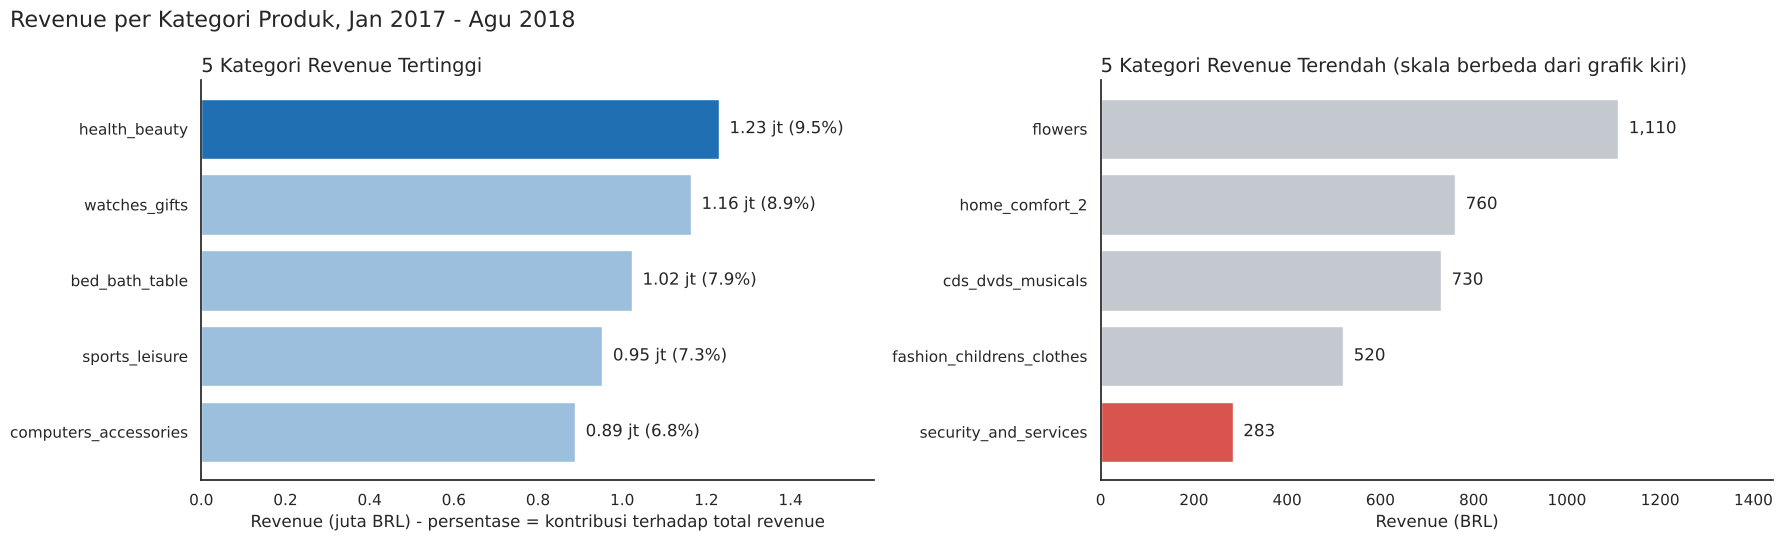

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

top5 = category_revenue.head(5).reset_index()
axes[0].barh(top5["product_category"], top5["revenue"] / 1e6, color=[BLUE] + [LIGHT_BLUE] * 4)
axes[0].invert_yaxis()
for i, (v, p) in enumerate(zip(top5["revenue"], top5["share_pct"])):
    axes[0].text(v / 1e6, i, f"  {v/1e6:.2f} jt ({p:.1f}%)", va="center")
axes[0].set_xlim(0, top5["revenue"].max() / 1e6 * 1.3)
axes[0].set_title("5 Kategori Revenue Tertinggi", fontsize=14, loc="left")
axes[0].set_xlabel("Revenue (juta BRL) - persentase = kontribusi terhadap total revenue")

bottom5 = category_revenue.tail(5).sort_values("revenue", ascending=False).reset_index()
axes[1].barh(bottom5["product_category"], bottom5["revenue"], color=[GREY] * 4 + [RED])
axes[1].invert_yaxis()
for i, v in enumerate(bottom5["revenue"]):
    axes[1].text(v, i, f"  {v:,.0f}", va="center")
axes[1].set_xlim(0, bottom5["revenue"].max() * 1.3)
axes[1].set_title("5 Kategori Revenue Terendah (skala berbeda dari grafik kiri)", fontsize=14, loc="left")
axes[1].set_xlabel("Revenue (BRL)")

for ax in axes:
    clean_axes(ax)
fig.suptitle("Revenue per Kategori Produk, Jan 2017 - Agu 2018", fontsize=16, x=0.01, ha="left")
plt.tight_layout()
plt.show()

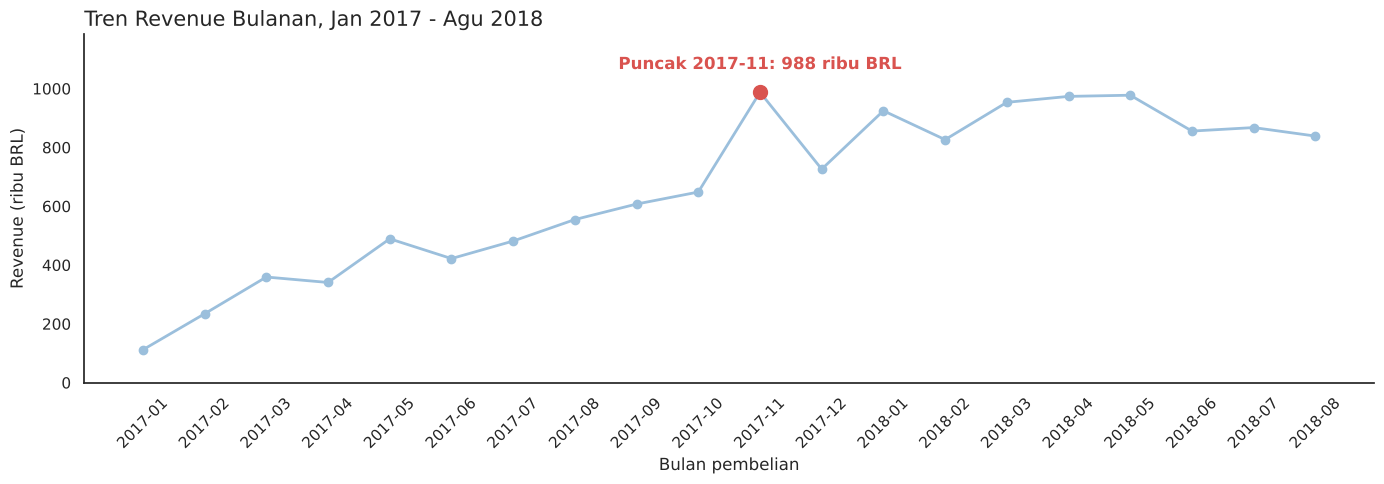

In [ ]:
months = monthly_revenue.index.astype(str)
revenue_k = monthly_revenue["revenue"] / 1000
peak = revenue_k.idxmax()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(months, revenue_k, marker="o", linewidth=2, color=LIGHT_BLUE)
ax.plot(str(peak), revenue_k.max(), "o", color=RED, markersize=10)
ax.annotate(f"Puncak {peak}: {revenue_k.max():,.0f} ribu BRL",
            xy=(str(peak), revenue_k.max()), xytext=(str(peak), revenue_k.max() * 1.08),
            ha="center", color=RED, fontweight="bold")
ax.set_ylim(0, revenue_k.max() * 1.2)
ax.set_title("Tren Revenue Bulanan, Jan 2017 - Agu 2018", fontsize=15, loc="left")
ax.set_xlabel("Bulan pembelian")
ax.set_ylabel("Revenue (ribu BRL)")
ax.tick_params(axis="x", rotation=45)
clean_axes(ax)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 1:**
- 5 kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang sekitar **40%** total revenue.
- Kategori terendah (mis. `security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`) hanya menghasilkan revenue di bawah 1.200 BRL selama 20 bulan.
- Revenue bulanan naik tajam dari ±112 ribu BRL (Jan 2017) menjadi puncak ±988 ribu BRL pada **November 2017** (periode Black Friday), lalu stabil di kisaran 830–980 ribu BRL sepanjang 2018.

### Pertanyaan 2: Keterlambatan pengiriman dan review score di 10 state teratas

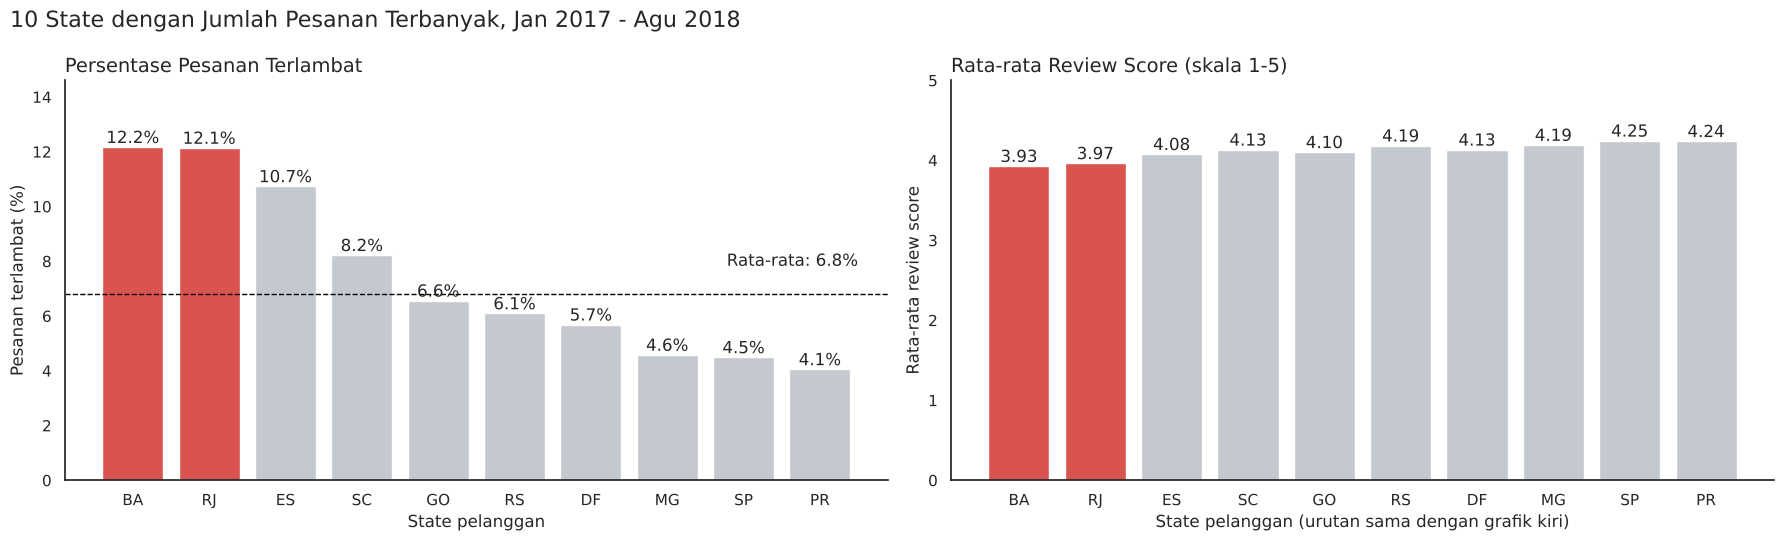

In [ ]:
state_plot = top10_state.sort_values("late_pct", ascending=False).reset_index()
bar_colors = [RED] * 2 + [GREY] * (len(state_plot) - 2)    # 2 state paling bermasalah disorot
avg_late = order_df["is_late"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

axes[0].bar(state_plot["customer_state"], state_plot["late_pct"], color=bar_colors)
for i, v in enumerate(state_plot["late_pct"]):
    axes[0].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
axes[0].axhline(avg_late, color="black", linestyle="--", linewidth=1)
axes[0].text(len(state_plot) - 0.5, avg_late + 0.9, f"Rata-rata: {avg_late:.1f}%", ha="right", va="bottom")
axes[0].set_ylim(0, state_plot["late_pct"].max() * 1.2)
axes[0].set_title("Persentase Pesanan Terlambat", fontsize=14, loc="left")
axes[0].set_xlabel("State pelanggan"); axes[0].set_ylabel("Pesanan terlambat (%)")

axes[1].bar(state_plot["customer_state"], state_plot["avg_review"], color=bar_colors)
for i, v in enumerate(state_plot["avg_review"]):
    axes[1].text(i, v, f"{v:.2f}", ha="center", va="bottom")
axes[1].set_ylim(0, 5)
axes[1].set_title("Rata-rata Review Score (skala 1-5)", fontsize=14, loc="left")
axes[1].set_xlabel("State pelanggan (urutan sama dengan grafik kiri)"); axes[1].set_ylabel("Rata-rata review score")

for ax in axes:
    clean_axes(ax)
fig.suptitle("10 State dengan Jumlah Pesanan Terbanyak, Jan 2017 - Agu 2018", fontsize=16, x=0.01, ha="left")
plt.tight_layout()
plt.show()

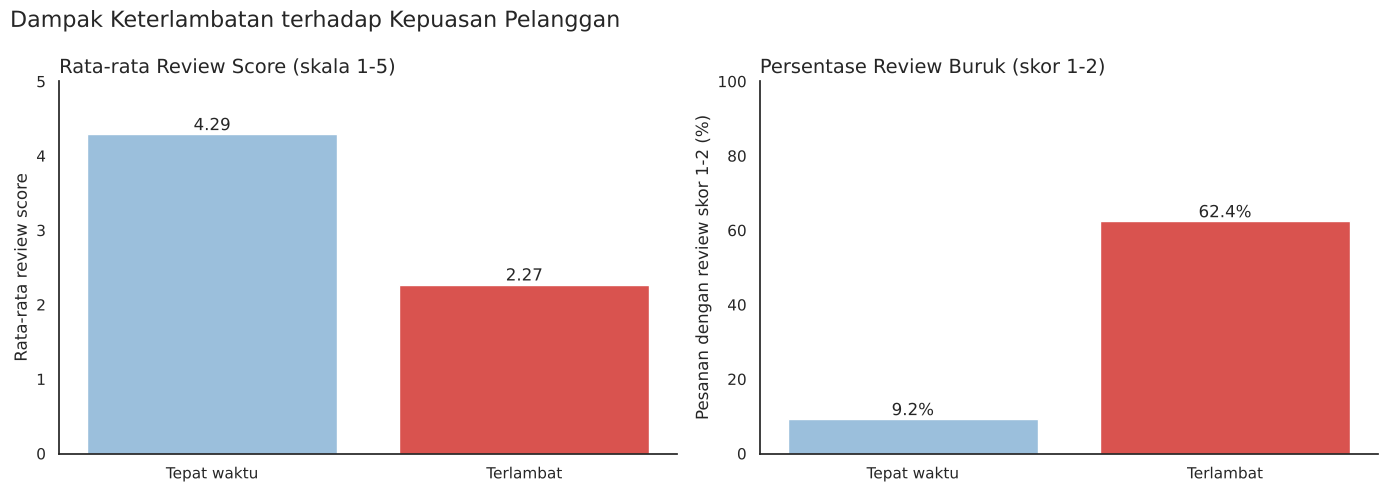

,avg_review,bad_review_pct
status,,
Tepat waktu,4.29,9.25
Terlambat,2.27,62.42


In [ ]:
timing = order_df.assign(status=order_df["is_late"].map({False: "Tepat waktu", True: "Terlambat"}))
timing_summary = timing.groupby("status").agg(
    avg_review=("review_score", "mean"),
    bad_review_pct=("review_score", lambda s: (s <= 2).sum() / s.notna().sum() * 100),
).loc[["Tepat waktu", "Terlambat"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = [LIGHT_BLUE, RED]

axes[0].bar(timing_summary.index, timing_summary["avg_review"], color=colors)
for i, v in enumerate(timing_summary["avg_review"]):
    axes[0].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=12)
axes[0].set_ylim(0, 5)
axes[0].set_title("Rata-rata Review Score (skala 1-5)", fontsize=14, loc="left")
axes[0].set_ylabel("Rata-rata review score")

axes[1].bar(timing_summary.index, timing_summary["bad_review_pct"], color=colors)
for i, v in enumerate(timing_summary["bad_review_pct"]):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=12)
axes[1].set_ylim(0, 100)
axes[1].set_title("Persentase Review Buruk (skor 1-2)", fontsize=14, loc="left")
axes[1].set_ylabel("Pesanan dengan review skor 1-2 (%)")

for ax in axes:
    clean_axes(ax); ax.set_xlabel("")
fig.suptitle("Dampak Keterlambatan terhadap Kepuasan Pelanggan", fontsize=16, x=0.01, ha="left")
plt.tight_layout()
plt.show()
timing_summary

**Insight Pertanyaan 2:**
- Hanya sekitar **6,8%** pesanan yang terlambat, tetapi dampaknya besar: rata-rata review score pesanan terlambat **2,27** vs **4,29** untuk pesanan tepat waktu (selisih ±2 poin), dan persentase review buruk (skor 1-2) naik dari ±9% menjadi ±62%.
- Di antara 10 state teratas, **RJ (12,1%)** dan **BA (12,2%)** punya persentase keterlambatan tertinggi (±2,7x lipat SP/PR/MG yang 4–5%), dan review score keduanya juga paling rendah (±3,93–3,97 dibanding ±4,25 di SP dan PR).

## Analisis Lanjutan (Opsional)

Tiga teknik analisis lanjutan (tanpa algoritma machine learning) diterapkan karena relevan dengan data e-commerce ini:
1. **RFM Analysis**: mengelompokkan pelanggan berdasarkan *Recency* (hari sejak pembelian terakhir), *Frequency* (jumlah pesanan), dan *Monetary* (total belanja), untuk menentukan segmen yang perlu dipertahankan atau diaktifkan kembali.
2. **Geospatial Analysis**: memetakan jumlah pesanan dan persentase keterlambatan per state pada koordinat geografis, agar pola wilayah bermasalah terlihat secara spasial.
3. **Binning (manual grouping)**: mengelompokkan lama pengiriman ke dalam interval (≤7, 8–14, 15–21, >21 hari) untuk mengetahui pada titik mana review score mulai turun.

### RFM Analysis

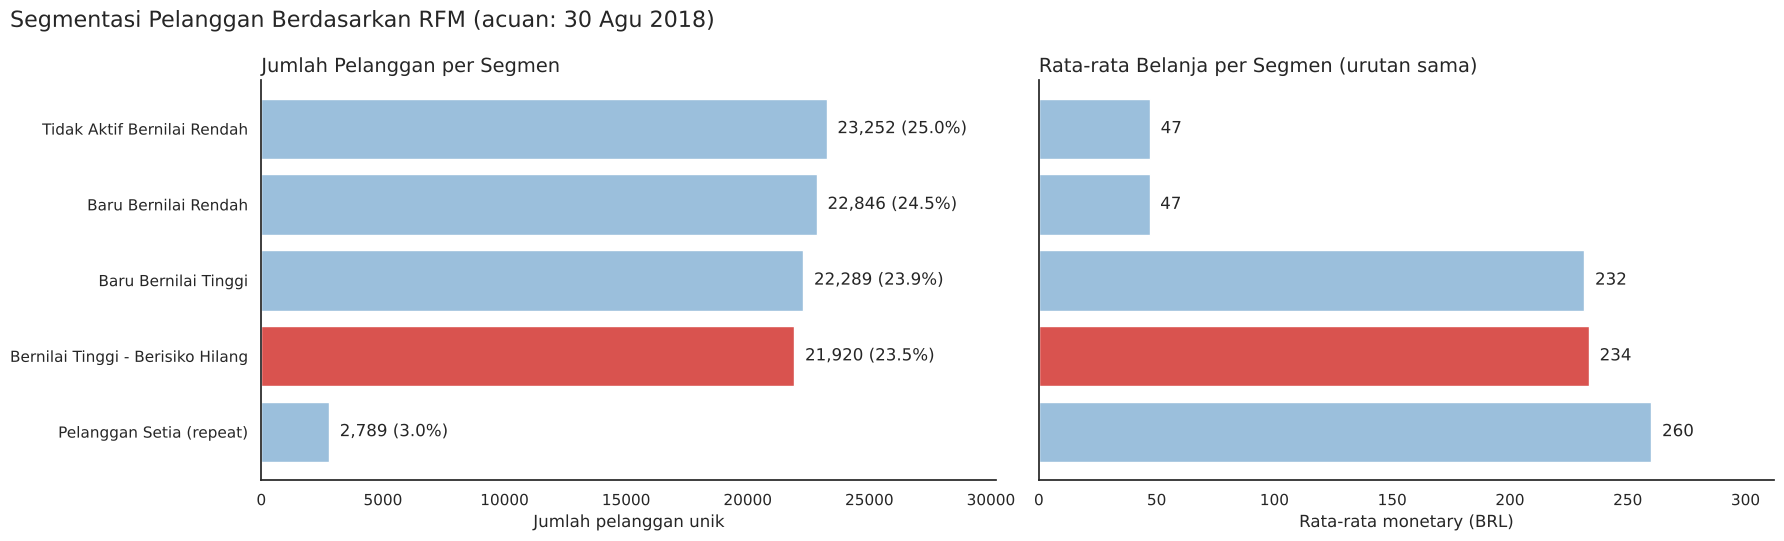

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

seg_order = segment_summary.sort_values("customers", ascending=False)
seg_colors = [RED if "Berisiko" in name else LIGHT_BLUE for name in seg_order.index]
axes[0].barh(seg_order.index, seg_order["customers"], color=seg_colors)
axes[0].invert_yaxis()
for i, (v, p) in enumerate(zip(seg_order["customers"], seg_order["share_pct"])):
    axes[0].text(v, i, f"  {v:,} ({p:.1f}%)", va="center")
axes[0].set_xlim(0, seg_order["customers"].max() * 1.3)
axes[0].set_title("Jumlah Pelanggan per Segmen", fontsize=14, loc="left")
axes[0].set_xlabel("Jumlah pelanggan unik")

axes[1].barh(seg_order.index, seg_order["avg_monetary"], color=seg_colors)
axes[1].invert_yaxis()
for i, v in enumerate(seg_order["avg_monetary"]):
    axes[1].text(v, i, f"  {v:,.0f}", va="center")
axes[1].set_xlim(0, seg_order["avg_monetary"].max() * 1.2)
axes[1].set_title("Rata-rata Belanja per Segmen (urutan sama)", fontsize=14, loc="left")
axes[1].set_xlabel("Rata-rata monetary (BRL)")
axes[1].set_yticklabels([])

for ax in axes:
    clean_axes(ax)
fig.suptitle("Segmentasi Pelanggan Berdasarkan RFM (acuan: 30 Agu 2018)", fontsize=16, x=0.01, ha="left")
plt.tight_layout()
plt.show()

**Insight RFM:**
- Hanya ±3% pelanggan (2.789 dari 93.096) yang pernah membeli lebih dari sekali, jadi basis pelanggan sangat bergantung pada pelanggan baru.
- Segmen **Bernilai Tinggi - Berisiko Hilang** (±21.900 pelanggan, ±23,6%, rata-rata belanja ±234 BRL, terakhir belanja ±362 hari lalu) adalah kandidat utama kampanye *win-back*, karena nilai belanjanya hampir sama dengan pelanggan setia (±260 BRL).

### Geospatial Analysis

Koordinat tiap state diambil dari median `geolocation_lat` dan `geolocation_lng` pada tabel geolocation (titik di luar wilayah Brasil dibuang karena anomali).
Peta di bawah adalah *bubble map* sederhana: ukuran gelembung = jumlah pesanan, warna = persentase pesanan terlambat.

In [ ]:
geo_df = pd.read_csv("data/geolocation_dataset.csv")

# titik di luar kotak koordinat Brasil dianggap anomali
geo_df = geo_df[geo_df["geolocation_lat"].between(-34, 6) & geo_df["geolocation_lng"].between(-74, -34)]
state_geo = (
    geo_df.groupby("geolocation_state")[["geolocation_lat", "geolocation_lng"]].median()
    .rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng"})
    .rename_axis("customer_state").reset_index()
)

geo_summary = state_summary.reset_index().merge(state_geo, on="customer_state", how="left")
geo_summary.to_csv("dashboard/state_geo.csv", index=False)
geo_summary.isna().sum().sum(), geo_summary.head()

(np.int64(0),
   customer_state  orders  late_pct  avg_review  avg_delivery_days    lat  \
 0             SP   40399      4.50        4.25               8.27 -23.53   
 1             RJ   12310     12.14        3.97              14.84 -22.87   
 2             MG   11319      4.59        4.19              11.52 -19.92   
 3             RS    5327      6.10        4.19              14.81 -29.80   
 4             PR    4903      4.06        4.24              11.51 -25.38   
 
      lng  
 0 -46.69  
 1 -43.24  
 2 -43.98  
 3 -51.25  
 4 -50.62  )

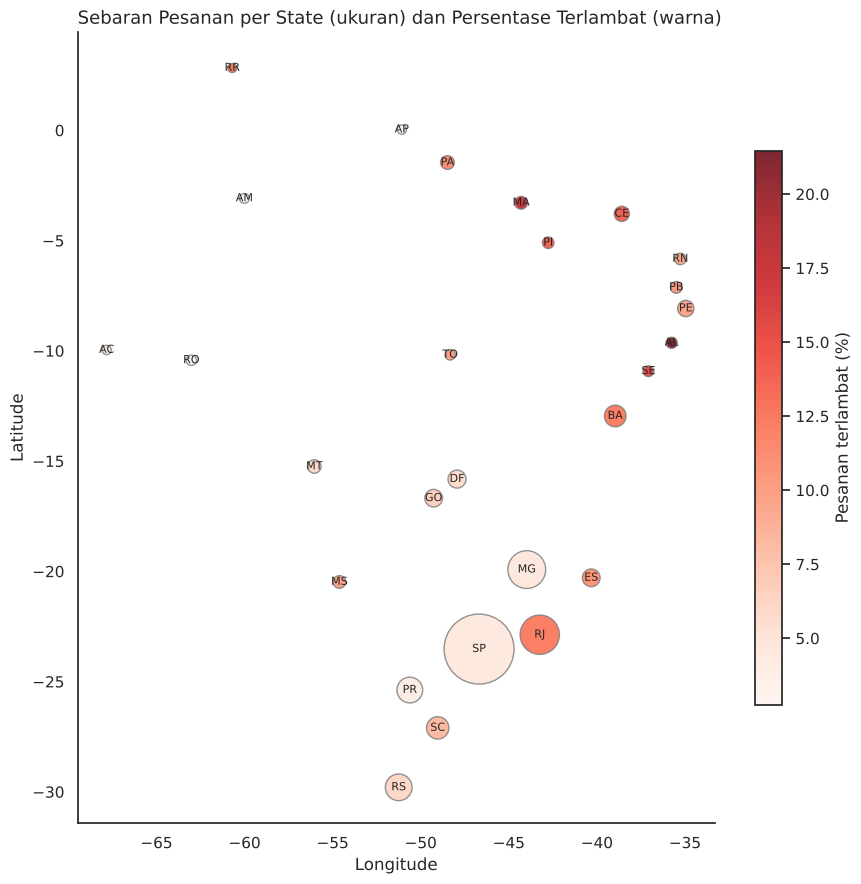

,customer_state,orders,late_pct,avg_review
19,AL,396,21.46,3.85
14,MA,713,17.53,3.83
20,SE,332,15.36,3.90
17,PI,475,13.89,3.99
11,CE,1273,13.83,3.94


In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(geo_summary["lng"], geo_summary["lat"],
                s=geo_summary["orders"] / geo_summary["orders"].max() * 2500 + 40,
                c=geo_summary["late_pct"], cmap="Reds", edgecolor="grey", alpha=0.85)
for _, r in geo_summary.iterrows():
    ax.text(r["lng"], r["lat"], r["customer_state"], ha="center", va="center", fontsize=8)
cbar = plt.colorbar(sc, ax=ax, shrink=0.7)
cbar.set_label("Pesanan terlambat (%)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Sebaran Pesanan per State (ukuran) dan Persentase Terlambat (warna)", fontsize=13, loc="left")
clean_axes(ax)
plt.tight_layout()
plt.show()

geo_summary.sort_values("late_pct", ascending=False)[["customer_state", "orders", "late_pct", "avg_review"]].head(5)

**Insight Geospatial:**
- Pesanan sangat terpusat di wilayah tenggara (SP, RJ, MG), dan pada wilayah ini SP serta MG justru punya keterlambatan paling rendah.
- State di utara dan timur laut (mis. AL, MA, SE) berwarna paling gelap: keterlambatannya tinggi (±15–21%), tetapi volume pesanannya kecil. Pola ini menunjukkan jarak ke pusat distribusi ikut memengaruhi ketepatan pengiriman.

### Binning: Lama Pengiriman vs Review Score

In [ ]:
delivery_bins = pd.cut(order_df["delivery_days"], bins=[-1, 7, 14, 21, 1000],
                       labels=["<= 7 hari", "8-14 hari", "15-21 hari", "> 21 hari"])
bin_summary = order_df.groupby(delivery_bins, observed=True).agg(
    orders=("order_id", "count"),
    avg_review=("review_score", "mean"),
    late_pct=("is_late", lambda s: s.mean() * 100),
)
bin_summary["orders_pct"] = bin_summary["orders"] / bin_summary["orders"].sum() * 100
bin_summary

,orders,avg_review,late_pct,orders_pct
delivery_days,,,,
<= 7 hari,33645,4.41,0.29,34.97
8-14 hari,36333,4.29,0.95,37.77
15-21 hari,15305,4.10,4.26,15.91
> 21 hari,10920,3.00,49.78,11.35


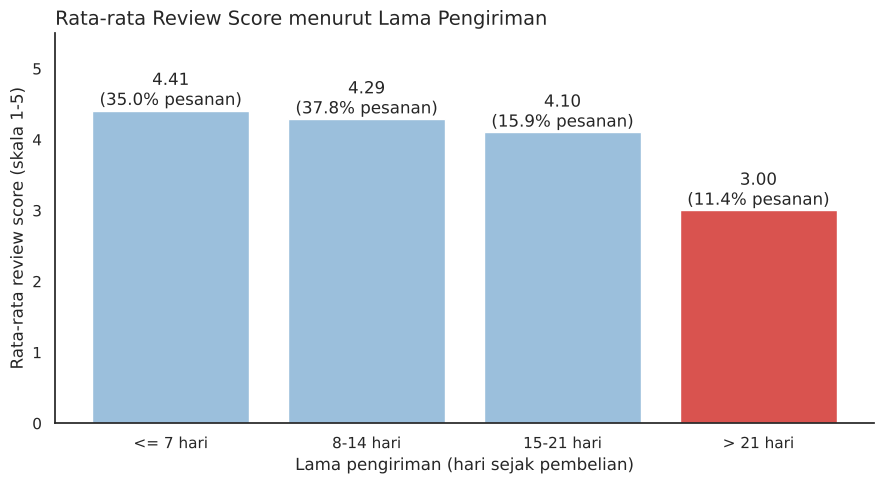

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(bin_summary.index.astype(str), bin_summary["avg_review"], color=[LIGHT_BLUE] * 3 + [RED])
for i, (v, p) in enumerate(zip(bin_summary["avg_review"], bin_summary["orders_pct"])):
    ax.text(i, v, f"{v:.2f}\n({p:.1f}% pesanan)", ha="center", va="bottom")
ax.set_ylim(0, 5.5)
ax.set_title("Rata-rata Review Score menurut Lama Pengiriman", fontsize=14, loc="left")
ax.set_xlabel("Lama pengiriman (hari sejak pembelian)"); ax.set_ylabel("Rata-rata review score (skala 1-5)")
clean_axes(ax)
plt.tight_layout()
plt.show()

**Insight Binning:**
- Review score turun seiring lama pengiriman: ±4,41 (≤7 hari), 4,29 (8–14 hari), 4,10 (15–21 hari), lalu anjlok ke **3,00** pada pengiriman di atas 21 hari.
- Kelompok >21 hari hanya 11,4% pesanan, tetapi hampir separuhnya (49,8%) terlambat dari estimasi. Kelompok ini adalah target utama perbaikan logistik.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Revenue sangat terkonsentrasi pada beberapa kategori. 5 kategori teratas (`health_beauty` ±1,23 jt BRL, `watches_gifts` ±1,16 jt, `bed_bath_table` ±1,02 jt, `sports_leisure` ±0,95 jt, `computers_accessories` ±0,89 jt) menyumbang ±40,4% total revenue, sedangkan 5 kategori terbawah masing-masing hanya menghasilkan di bawah 1.200 BRL. Revenue bulanan tumbuh dari ±112 ribu BRL (Jan 2017) ke puncak ±988 ribu BRL (Nov 2017) lalu mendatar di 830–980 ribu BRL pada 2018, dengan sedikit penurunan pada Juni–Agustus 2018 setelah puncak Mei 2018.
- **Conclusion pertanyaan 2:** Keterlambatan pengiriman memukul kepuasan pelanggan: review score rata-rata turun dari 4,29 (tepat waktu) menjadi 2,27 (terlambat), meski hanya ±6,8% pesanan yang terlambat. Pada 10 state teratas, RJ dan BA paling bermasalah (±12% terlambat, review ±3,93–3,97), sedangkan SP, PR, dan MG paling baik (4–5% terlambat, review ±4,19–4,25).
- **Conclusion analisis lanjutan:** (RFM) Hanya ±3% pelanggan yang melakukan pembelian ulang, sehingga retensi menjadi peluang pertumbuhan terbesar. Segmen bernilai tinggi yang berisiko hilang (±23,6% pelanggan) perlu ditargetkan untuk kampanye *win-back*. (Geospatial) Pesanan terpusat di SP, RJ, dan MG, sedangkan state di utara dan timur laut seperti AL, MA, dan SE punya persentase keterlambatan tertinggi (±15–21%) dengan volume kecil. (Binning) Review score turun dari 4,41 (pengiriman ≤7 hari) menjadi 3,00 (>21 hari), dan hampir separuh pesanan di kelompok >21 hari terlambat dari estimasi.

**Rekomendasi Action Item:**

1. **Prioritaskan stok dan promosi** pada 5 kategori teratas, terutama menjelang periode puncak (Oktober–November). Evaluasi kategori dengan revenue sangat rendah: gabungkan ke kategori lain, kurangi katalog, atau uji promosi kecil sebelum dihentikan.
2. **Perbaiki logistik di RJ dan BA terlebih dahulu** (negosiasi ulang SLA dengan jasa kirim, pertimbangkan gudang/*fulfillment* yang lebih dekat, dan buat estimasi pengiriman yang lebih realistis). Targetkan persentase keterlambatan di kedua state turun mendekati level SP/MG (±5%).
3. **Jalankan kampanye retensi** (voucher pembelian kedua, *win-back* untuk segmen "Bernilai Tinggi - Berisiko Hilang") dengan target menaikkan tingkat pembelian ulang dari ±3% ke level yang lebih tinggi pada periode berikutnya.